# Copper forecasting V22 — Fresh SA-LSTM | WTI-only input

**Kaggle Run All**, toàn bộ huấn luyện sử dụng duy nhất `Copper, Aluminium, Tin, WTI`. Chạy lại Simulated Annealing trên train/validation của bộ WTI mới; không tái sử dụng HP cache V21 và **không chạy lại Legacy14/Paper3**. Dùng kết quả cũ làm đối chứng khi viết báo cáo sau.

Các mô hình: Naive, LSTM, SimpleRNN, fixed paper-HP LSTM, fresh SA-tuned LSTM. SA là tối ưu hyperparameters, không phải tầng mạng. Paper-HP LSTM là tái dựng có giả định, không phải reproduction tuyệt đối.

## 1. Environment and configuration

In [3]:
from pathlib import Path
import os, gc, json, time, math, hashlib, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf

# ─── CHẾ ĐỘ THỰC NGHIỆM ─────────────────────────────────────────────────────────
# 'QUICK_MODE': Smoke test logic, vẫn thực hiện SA search nhỏ
# 'FULL_MODE': SA search trên train/validation rồi train final với 100 epochs tối đa
# 'EXACT_PAPER_MODE': Chạy đúng 100 epochs cố định không early stopping, 3 tỷ lệ bài báo (0.9, 0.925, 0.95)
MODE = 'FULL_MODE'
MODE_CFG = {
    'QUICK_MODE':       {'epochs': 5,   'search_epochs': 3,  'sa_evals': 4,   'earlystop': True},
    'FULL_MODE':        {'epochs': 100, 'search_epochs': 15, 'sa_evals': 16, 'earlystop': True},
    'EXACT_PAPER_MODE': {'epochs': 100, 'search_epochs': 25, 'sa_evals': 40, 'earlystop': False}
}
CFG = MODE_CFG[MODE]

# ─── THIẾT LẬP PHƯƠNG PHÁP LUẬN V20 & BÀI BÁO GỐC ───────────────────────────────
LOOKBACK = 22
HORIZON = 1          # Cố định HORIZON=1: Protocol V20 (true forecasting, không look-ahead)
# Bài báo Chen et al. (2023) sử dụng 3 tỷ lệ phân chia: 0.90, 0.925, 0.95
# V20 bổ sung thêm 0.80 để khảo sát tính vững chắc trên cửa sổ dài hạn
RATIOS = (0.80, 0.90, 0.925, 0.95)  # Paper's three ratios; strategies are all checked at PRIMARY_RATIO
PRIMARY_RATIO = 0.90
BATCH_SIZE = 64      # Chuẩn 64 như Bảng 4 bài báo
SEED = 42
# Full matrix is compute-intensive. No automatic timeout or partial success claim.
JOB_START = time.monotonic()

# ─── CHỈ BỘ ĐẶC TRƯNG WTI MỚI ────────────────────────────────────────────────
FEATURE_SETS = {
    'wti_replacement_with_copper': ['Copper', 'Aluminium', 'Tin', 'WTI']
}
# Fresh SA search for the sole WTI feature set; no V21 cached HP.

SCHEMES = ('expanding', 'rolling_756', 'recency_weighted')

# ─── ĐƯỜNG DẪN VÀ CHECKPOINT ──────────────────────────────────────────────────
DATASET_CANDIDATES = [
    Path('/kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'),
    Path('/kaggle/input/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'),
    Path('data/processed/dataset_9_commodities_daily.csv'),
    Path('data/raw/dataset_9_commodities_daily.csv'),
    Path('dataset_9_commodities_daily.csv')
]

OUT = Path('/kaggle/working/copper_sa_lstm_wti_only_v22') if Path('/kaggle/working').exists() else Path('copper_sa_lstm_wti_only_v22')
OUT.mkdir(parents=True, exist_ok=True)

# Cố định tính ngẫu nhiên
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass

print('═'*75)
print(f'COPPER SA-LSTM BENCHMARK | CHẾ ĐỘ: {MODE}')
print(f'Epochs: {CFG["epochs"]} (Chuẩn bài báo 100) | Batch Size: {BATCH_SIZE} | EarlyStop: {CFG["earlystop"]}')
print(f'Horizon: {HORIZON} | Lookback: {LOOKBACK} | Seed: {SEED}')
print(f'Splits: {[f"{r*100:g}%" for r in RATIOS]}')
print(f'Feature Sets: {list(FEATURE_SETS.keys())}')
print(f'GPU Devices: {tf.config.list_physical_devices("GPU")}')
print(f'Output Directory: {OUT.resolve()}')

print('SA search ENABLED: fresh search on train/validation for EACH feature variant.')


═══════════════════════════════════════════════════════════════════════════
COPPER SA-LSTM BENCHMARK | CHẾ ĐỘ: FULL_MODE
Epochs: 100 (Chuẩn bài báo 100) | Batch Size: 64 | EarlyStop: True
Horizon: 1 | Lookback: 22 | Seed: 42
Splits: ['80%', '90%', '92.5%', '95%']
Feature Sets: ['wti_replacement_with_copper']
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Output Directory: /kaggle/working/copper_sa_lstm_wti_only_v22
SA search ENABLED: fresh search on train/validation for EACH feature variant.


## 2. Input dataset and quality

In [4]:
TARGET = 'Copper'
REQUIRED_COLS = ['Copper', 'Aluminium', 'Tin', 'WTI']

DATA_PATH = next((p for p in DATASET_CANDIDATES if p.is_file()), None)
if DATA_PATH is None and Path('/kaggle/input').exists():
    matches = list(Path('/kaggle/input').rglob('dataset_9_commodities_daily.csv'))
    if len(matches) == 1: DATA_PATH = matches[0]
if DATA_PATH is None:
    raise FileNotFoundError('Không tìm thấy file dataset_9_commodities_daily.csv. Vui lòng kiểm tra đường dẫn.')

raw = pd.read_csv(DATA_PATH)
if 'Date' not in raw.columns or TARGET not in raw.columns:
    raise KeyError('Tệp CSV phải có cột Date và Copper.')

raw['Date'] = pd.to_datetime(raw['Date'], errors='coerce')
if raw['Date'].isna().any(): raise ValueError('Cột Date có dòng không hợp lệ.')
if raw['Date'].duplicated().any(): raise ValueError('Có ngày bị trùng lặp; cần xử lý nguồn dữ liệu.')

for col in REQUIRED_COLS:
    if col not in raw.columns: raise ValueError(f'Thiếu cột bắt buộc: {col}')
    raw[col] = pd.to_numeric(raw[col], errors='coerce')

raw = raw.sort_values('Date').reset_index(drop=True)
quality = pd.DataFrame({
    'column': raw.columns,
    'missing': raw.isna().sum().values,
    'dtype': raw.dtypes.astype(str).values
})
quality.to_csv(OUT / 'data_quality.csv', index=False)

# Làm sạch dữ liệu trên hợp các biến cần dùng
data = raw.dropna(subset=REQUIRED_COLS).reset_index(drop=True)
assert len(data) > 1000 and data['Date'].is_monotonic_increasing
assert all((data[c] > 0).all() for c in REQUIRED_COLS), 'Giá <= 0: cần kiểm toán dữ liệu trước khi huấn luyện.'

dataset_sha256 = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
(OUT / 'dataset_fingerprint.txt').write_text(dataset_sha256)

print(f'Nạp dữ liệu thành công từ: {DATA_PATH}')
print(f'Tổng số phiên: {len(data):,} phiên | Từ ngày {data.Date.iloc[0].date()} đến {data.Date.iloc[-1].date()}')
print(f'SHA256 Fingerprint: {dataset_sha256[:16]}...')
display(quality[quality['column'].isin(['Date'] + REQUIRED_COLS)])

Nạp dữ liệu thành công từ: /kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv
Tổng số phiên: 2,710 phiên | Từ ngày 2016-01-13 đến 2026-11-13
SHA256 Fingerprint: 9580ede12d474c8f...


,column,missing,dtype
0,Date,0,datetime64[ns]
1,Copper,0,float64
2,Aluminium,0,float64
4,Tin,0,float64
8,WTI,0,float64


## 3. Time-safe train / validation / test and sliding windows

In [5]:
def make_context(frame, ratio, scheme='expanding', feature_set='wti_replacement_with_copper', val_fraction=0.10):
    n = len(frame)
    split = int(n * ratio)
    val_start = int(split * (1.0 - val_fraction))
    fit_start = 0 if scheme != 'rolling_756' else max(0, val_start - 756)
    cols = FEATURE_SETS[feature_set]
    assert LOOKBACK + 25 < val_start < split < n
    assert val_start - fit_start > LOOKBACK + 10
    # Train-only scaling: no future statistics leak into scaler.
    xsc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][cols])
    ysc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    x = xsc.transform(frame[cols]).astype('float32')
    y = ysc.transform(frame[[TARGET]]).ravel().astype('float32')
    prev = np.r_[np.nan, y[:-1]]
    def block(start, end, restrict_train=False):
        indices = np.arange(max(start, LOOKBACK), end)
        if restrict_train:
            indices = indices[indices-LOOKBACK >= fit_start]
        X = np.stack([x[t-LOOKBACK:t] for t in indices]).astype('float32')
        return {'idx': indices, 'X': X, 'y': y[indices],
                'prev': prev[indices].astype('float32'),
                'date': frame.Date.iloc[indices].to_numpy()}
    tr = block(fit_start, val_start, True)
    va = block(val_start, split)
    te = block(split, n)
    assert tr['idx'][-1] < va['idx'][0] < te['idx'][0]
    assert xsc.n_samples_seen_ == val_start - fit_start
    assert len(tr['X']) > 0 and tr['X'].shape[1:] == (LOOKBACK, len(cols))
    # Last X timestamp is always t-1. Verify Copper only if included.
    if 'Copper' in cols:
        copper_col = cols.index('Copper')
        copper_raw_in_x = xsc.inverse_transform(x[tr['idx']-1])[:, copper_col]
        copper_true = frame.iloc[tr['idx']-1]['Copper'].to_numpy()
        assert np.allclose(copper_raw_in_x, copper_true, atol=1e-4)
    return {'train': tr, 'val': va, 'test': te, 'xsc': xsc, 'ysc': ysc,
            'features': cols, 'feature_set': feature_set, 'horizon': 1,
            'ratio': float(ratio), 'scheme': scheme,
            'fit_start': fit_start, 'val_start': val_start, 'test_start': split}

for feature_set in FEATURE_SETS:
    ctx = make_context(data, PRIMARY_RATIO, 'expanding', feature_set)
    assert ctx['train']['X'].shape[-1] == len(FEATURE_SETS[feature_set])
    assert np.array_equal(ctx['test']['idx'], make_context(data, PRIMARY_RATIO, 'expanding', 'wti_replacement_with_copper')['test']['idx'])
    print(feature_set, ctx['train']['X'].shape, ctx['val']['X'].shape, ctx['test']['X'].shape)
print('PASS: Horizon=1 and WTI-only feature integrity checks')


wti_replacement_with_copper (2173, 22, 4) (244, 22, 4) (271, 22, 4)
PASS: Horizon=1 and WTI-only feature integrity checks


## 4. Model builders: original paper fixed HP; new SA searches units and LR on validation

In [6]:
PAPER_SA_LSTM_HP = {'units_1': 39, 'units_2': 111, 'learning_rate': 5e-5}

def build_baseline_lstm(input_shape, hp=None):
    """Mô hình LSTM chuẩn không tối ưu SA (Protocol V20 baseline)."""
    model = tf.keras.Sequential(name='Baseline_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(64, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(32))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

def build_paper_sa_lstm(input_shape, hp=None):
    """Kiến trúc SA-LSTM với siêu tham số công bố trong bài báo Chen et al. (2023)."""
    model = tf.keras.Sequential(name='Paper_SA_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(39, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(111, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(5e-5), loss='mse')
    return model

def build_sa_lstm(input_shape, hp=None):
    """Kiến trúc SA-LSTM nhận siêu tham số linh hoạt do SA tìm kiếm (chỉ H=1, HP tìm mới riêng cho từng feature set)."""
    h = hp or PAPER_SA_LSTM_HP
    u1 = int(h.get('units_1', 39))
    u2 = int(h.get('units_2', 111))
    lr = float(h.get('learning_rate', 5e-5))
    
    model = tf.keras.Sequential(name='Reoptimized_SA_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(u1, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(u2, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse')
    return model

# Đặt alias tương thích ngược nếu có đoạn gọi tên riêng
build_sa_lstm_paper3 = build_sa_lstm
build_sa_lstm_legacy14 = build_sa_lstm

print('Đã khởi tạo xong các hàm dựng mô hình LSTM (bao gồm build_sa_lstm).')

def build_baseline_rnn(input_shape, hp=None):
    """SimpleRNN baseline with two recurrent layers and comparable head."""
    model = tf.keras.Sequential(name='Baseline_RNN')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.SimpleRNN(64, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.SimpleRNN(32))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model


Đã khởi tạo xong các hàm dựng mô hình LSTM (bao gồm build_sa_lstm).


## 5. Training and metrics (no test prediction during SA search)

In [7]:
def reset_keras(seed=SEED):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(int(seed))

def sample_weights(length, scheme, half_life=252):
    if scheme != 'recency_weighted': return None
    ages = np.arange(length - 1, -1, -1, dtype='float64')
    w = np.exp(-np.log(2) * ages / half_life)
    return (w / w.mean()).astype('float32')

def evaluate_predictions(ctx, model_name, p_val, p_test, seed=SEED, extras=None):
    ysc = ctx['ysc']; va = ctx['val']; te = ctx['test']
    def original(z): return ysc.inverse_transform(np.asarray(z).reshape(-1, 1)).ravel()
    
    # 1. Dịch ngược về giá gốc (USD)
    y_true = original(te['y'])
    pred = original(p_test)
    base = original(te['prev'])
    
    delta_pred = pred - base
    delta_true = y_true - base
    
    # 2. Tính các độ đo trên giá gốc (RAW - USD) khớp 100% với V20
    mae = float(mean_absolute_error(y_true, pred))
    rmse = float(np.sqrt(mean_squared_error(y_true, pred)))
    mse = float(mean_squared_error(y_true, pred))  # DỊCH NGƯỢC LẠI GIÁ GỐC (USD^2) - KHỚP V20
    base_mae = float(mean_absolute_error(y_true, base))
    improvement = float(100.0 * (base_mae - mae) / base_mae) if base_mae > 0 else 0.0
    
    # 3. Tính các độ đo trên thang đo chuẩn hóa (SCALED [0, 1])
    val_mse_scaled = float(mean_squared_error(va['y'], p_val))
    mse_scaled = float(mean_squared_error(te['y'], p_test)) if p_test is not None else np.nan
    
    # 4. Tính Directional Accuracy và các thống kê kiểm toán phần dư
    dir_acc = float(100.0 * np.mean(np.sign(delta_pred) == np.sign(delta_true))) if model_name != 'naive' else np.nan
    delta_pred_std = float(np.std(delta_pred))
    delta_true_std = float(np.std(delta_true))
    delta_pred_mean_abs = float(np.mean(np.abs(delta_pred)))
    pred_delta_corr = float(np.corrcoef(delta_pred, delta_true)[0, 1]) if delta_pred_std > 1e-12 else np.nan
    
    row = {
        'model': model_name,
        'feature_set': ctx['feature_set'],
        'copper_history': 'Copper' in ctx['features'],
        'feature_group': ctx['feature_set'].split('_')[0],
        'scheme': ctx['scheme'],
        'ratio': ctx['ratio'],
        'seed': int(seed),
        'n_test': len(y_true),
        'mae': mae,
        'rmse': rmse,
        'mse': mse,                        # GIÁ GỐC DỊCH NGƯỢC (USD^2) - KHỚP V20
        'mse_scaled': mse_scaled,          # SCALED TRÊN TẬP TEST [0, 1]
        'mae_naive': base_mae,
        'mae_improvement_pct': improvement,
        'val_mse_scaled': val_mse_scaled,  # SCALED TRÊN TẬP VALIDATION [0, 1] - KHỚP V20
        'directional_accuracy_pct': dir_acc,
        'delta_pred_std_raw': delta_pred_std,
        'delta_true_std_raw': delta_true_std,
        'delta_pred_mean_abs_raw': delta_pred_mean_abs,
        'pred_delta_corr': pred_delta_corr,
        'test_start': str(pd.Timestamp(te['date'][0]).date()),
        'fit_start': str(data.Date.iloc[ctx['fit_start']].date())
    }
    if extras: row.update(extras)
    
    predictions = pd.DataFrame({
        'Date': te['date'],
        'ratio': ctx['ratio'],
        'scheme': ctx['scheme'],
        'feature_set': ctx['feature_set'],
        'copper_history': 'Copper' in ctx['features'],
        'feature_group': ctx['feature_set'].split('_')[0],
        'model': model_name,
        'seed': int(seed),
        'actual': y_true,
        'pred': pred,
        'naive': base,
        'pred_delta': delta_pred,
        'actual_delta': delta_true
    })
    return row, predictions

def fit_predict_model(builder, ctx, hp=None, seed=SEED, epochs=None, patience=None, is_search=False, skip_test=False):
    reset_keras(seed)
    tr, va, te = ctx['train'], ctx['val'], ctx['test']
    model = builder(tr['X'].shape[1:], hp)
    
    cb = []
    if CFG['earlystop']:
        pat = patience if patience is not None else (4 if is_search else 9)
        cb.append(tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=pat, restore_best_weights=True))
        
    ep = epochs if epochs is not None else (CFG['search_epochs'] if is_search else CFG['epochs'])
    weights = sample_weights(len(tr['idx']), ctx['scheme'])
    
    start_t = time.perf_counter()
    hist = model.fit(
        tr['X'], tr['y'],
        validation_data=(va['X'], va['y']),
        epochs=ep,
        batch_size=BATCH_SIZE,
        sample_weight=weights,
        callbacks=cb,
        shuffle=False,
        verbose=0
    )
    fit_sec = time.perf_counter() - start_t
    
    pv = model.predict(va['X'], verbose=0).ravel()
    pt = model.predict(te['X'], verbose=0).ravel() if not skip_test else None
    val_mse = float(mean_squared_error(va['y'], pv))
    epochs_run = len(hist.history['loss'])
    
    del model
    reset_keras(seed)
    return {'val_pred': pv, 'test_pred': pt, 'val_mse': val_mse, 'seconds': fit_sec, 'epochs_run': epochs_run}

## 6. Fresh Simulated Annealing search — WTI-only

Chỉ tìm lại hyperparameters cho `Copper, Aluminium, Tin, WTI`, dùng train/validation của split 80/20 Expanding. Không đọc HP cached từ V21, không chọn HP theo test. SA search sử dụng budget được khai báo trong `MODE_CFG`.

In [8]:
# FRESH SA search: independent result for each feature-set; test never used to choose HP.
PAPER_SA_LSTM_HP = {'units_1':39, 'units_2':111, 'learning_rate':5e-5}
SA_SPACE = {'units_1':(16,96), 'units_2':(24,160), 'learning_rate':(1e-5,3e-3)}
SA_START = {'units_1':39, 'units_2':111, 'learning_rate':5e-5}
SA_PATIENCE = 4
SA_SEED = 2026
SA_PATH = OUT/'sa_search_trials.csv'

# Validation windows and scalers are fit ONLY on the train side (make_context).
def clip_hp(h):
    return {'units_1':int(np.clip(round(h['units_1']), *SA_SPACE['units_1'])),
            'units_2':int(np.clip(round(h['units_2']), *SA_SPACE['units_2'])),
            'learning_rate':float(np.clip(h['learning_rate'], *SA_SPACE['learning_rate']))}

def neighbor(h, rng, temp):
    # SA neighborhood defined in architecture space and log-LR space.
    h = dict(h); dim = rng.choice(['units_1','units_2','learning_rate'])
    if dim == 'learning_rate':
        h[dim] = float(h[dim] * np.exp(rng.normal(0, 0.65)))
    else:
        h[dim] = int(h[dim] + rng.choice([-1,1])*rng.choice([8,16,24]))
    return clip_hp(h)

def run_sa_for_variant(feature_set, budget, seed):
    ctx = make_context(data, min(RATIOS), 'expanding', feature_set)
    rng = np.random.default_rng(seed)
    current = clip_hp(SA_START); best = dict(current)
    current_loss = float('inf'); best_loss = float('inf')
    log = []
    for k in range(budget):
        temperature = float(max(0.05, 1.0 * 0.88**k))
        proposal = dict(current) if k == 0 else neighbor(current, rng, temperature)
        # Different controlled trial seed for each candidate; SA random proposal sequence reproducible.
        result = fit_predict_model(build_sa_lstm,ctx,hp=proposal,seed=seed+k,
                  epochs=CFG['search_epochs'],patience=SA_PATIENCE,is_search=True,skip_test=True)
        score = float(result['val_mse'])
        if not np.isfinite(score): raise RuntimeError('Non-finite SA validation loss')
        # Use a scale-adaptive temperature; raw MSE can be tiny.
        effective_temp = max(1e-8, temperature * max(score, current_loss if np.isfinite(current_loss) else score, 1e-5))
        accept = (score <= current_loss) or (rng.random() < np.exp(-max(0.0,score-current_loss)/effective_temp))
        if accept: current, current_loss = dict(proposal), score
        if score < best_loss: best, best_loss = dict(proposal), score
        entry = {'feature_set':feature_set,'trial':k+1,'temperature':temperature,
                 'val_mse_scaled':score,'accepted':bool(accept),'best_val_mse_scaled':best_loss,
                 'epochs_run':int(result['epochs_run']),'fit_seconds':float(result['seconds']),**proposal}
        log.append(entry)
        pd.DataFrame([entry]).to_csv(SA_PATH,mode='a',header=not SA_PATH.exists(),index=False)
        print(f'SA {feature_set} [{k+1}/{budget}]: val={score:.6f}, best={best_loss:.6f}, accepted={accept}',flush=True)
    return best,log

# Start a clean SA search; never silently reuse old V21 HP.
if SA_PATH.exists(): SA_PATH.unlink()
sa_best_cache = {}
sa_logs = []
for feature_number,feature_set in enumerate(FEATURE_SETS):
    best, history = run_sa_for_variant(feature_set,int(CFG['sa_evals']), SA_SEED+feature_number*1000)
    sa_best_cache[feature_set] = best
    sa_logs.extend(history)
    (OUT/'fresh_sa_best_hp.json').write_text(json.dumps({
        'search_feature_sets':FEATURE_SETS,'search_seed':SA_SEED,'search_budget_per_variant':CFG['sa_evals'],
        'search_epochs':CFG['search_epochs'],'reference_ratio':min(RATIOS),'reference_scheme':'expanding',
        'paper_fixed_hp':PAPER_SA_LSTM_HP,'fresh_sa_best':sa_best_cache},indent=2),encoding='utf-8')
print('FRESH SA SEARCH COMPLETED (no test labels used for HP selection)')
display(pd.DataFrame([{'feature_set':k,**v} for k,v in sa_best_cache.items()]))


SA wti_replacement_with_copper [1/16]: val=0.003729, best=0.003729, accepted=True
SA wti_replacement_with_copper [2/16]: val=0.003526, best=0.003526, accepted=True
SA wti_replacement_with_copper [3/16]: val=0.003425, best=0.003425, accepted=True
SA wti_replacement_with_copper [4/16]: val=0.005720, best=0.003425, accepted=False
SA wti_replacement_with_copper [5/16]: val=0.003892, best=0.003425, accepted=True
SA wti_replacement_with_copper [6/16]: val=0.003229, best=0.003229, accepted=True
SA wti_replacement_with_copper [7/16]: val=0.005407, best=0.003229, accepted=False
SA wti_replacement_with_copper [8/16]: val=0.006945, best=0.003229, accepted=False
SA wti_replacement_with_copper [9/16]: val=0.006680, best=0.003229, accepted=False
SA wti_replacement_with_copper [10/16]: val=0.003599, best=0.003229, accepted=True
SA wti_replacement_with_copper [11/16]: val=0.004640, best=0.003229, accepted=True
SA wti_replacement_with_copper [12/16]: val=0.003797, best=0.003229, accepted=True
SA wti_re

,feature_set,units_1,units_2,learning_rate
0,wti_replacement_with_copper,47,127,0.00005


## 7. Benchmark — WTI-only across ratios and schemes

Chạy Naive, LSTM, SimpleRNN, fixed paper-HP LSTM và fresh-SA LSTM. Không huấn luyện các feature sets khác.

In [9]:
RESULT_CSV = OUT / 'results_h1_ablation.csv'
PRED_CSV = OUT / 'predictions_h1_ablation.csv'
# 90/10 runs 3 schemes; all other ratios run Expanding only. SA HP tuned on 80/20 validation (before ALL test windows).
# Default: recompute cleanly on every Run All, to avoid mixing older results/settings.
# Optional set True to resume interrupted runs with identical configuration.
RESUME = False
RUN_FINGERPRINT = hashlib.sha256(json.dumps({'mode':MODE,'sa_search_trials':CFG['sa_evals'],'ratios':RATIOS,'schemes':SCHEMES,
    'features':FEATURE_SETS,'sa':sa_best_cache,'seed':SEED,'lookback':LOOKBACK,'horizon':HORIZON}, sort_keys=True).encode()).hexdigest()[:16]
if not RESUME:
    for f in [RESULT_CSV, PRED_CSV]:
        if f.exists(): f.unlink()
RESULT_ROWS = pd.read_csv(RESULT_CSV).to_dict('records') if RESULT_CSV.exists() else []

def has_job_completed(model_name, feature_set, scheme, ratio, seed=SEED):
    return any(str(r.get('run_fingerprint')) == RUN_FINGERPRINT and
               str(r.get('model')) == str(model_name) and
               str(r.get('feature_set')) == str(feature_set) and
               str(r.get('scheme')) == str(scheme) and
               abs(float(r.get('ratio', -1)) - float(ratio)) < 1e-6 and
               int(r.get('seed', -1)) == int(seed) for r in RESULT_ROWS)

def record_evaluation(row, pred_df):
    row['run_fingerprint'] = RUN_FINGERPRINT
    pred_df['run_fingerprint'] = RUN_FINGERPRINT
    RESULT_ROWS.append(row)
    pd.DataFrame(RESULT_ROWS).to_csv(RESULT_CSV, index=False)
    pred_df.to_csv(PRED_CSV, mode='a', header=not PRED_CSV.exists(), index=False)

MODEL_CONFIGS = [
    ('naive', None),
    ('baseline_lstm', build_baseline_lstm),
    ('baseline_rnn', build_baseline_rnn),
    ('paper_sa_lstm', build_paper_sa_lstm),
    ('reopt_sa_lstm', build_sa_lstm),
]
evaluation_jobs = [(feature_set, scheme, ratio, model_name, builder)
                   for ratio in RATIOS for scheme in (SCHEMES if ratio == PRIMARY_RATIO else ('expanding',))
                   for feature_set in FEATURE_SETS
                   for model_name, builder in MODEL_CONFIGS]
print('Planned benchmark jobs:',len(evaluation_jobs),'(including Naive; fresh SA already completed).')
for i, (feature_set, scheme, ratio, model_name, builder) in enumerate(evaluation_jobs, 1):
    if has_job_completed(model_name, feature_set, scheme, ratio):
        continue
    ctx = make_context(data, ratio, scheme, feature_set)
    hp = (PAPER_SA_LSTM_HP if model_name == 'paper_sa_lstm' else
          sa_best_cache[feature_set] if model_name == 'reopt_sa_lstm' else None)
    if model_name == 'naive':
        pv, pt = ctx['val']['prev'], ctx['test']['prev']
        extras = {'epochs_run': 0, 'fit_seconds': 0.0, 'hp_config': 'naive'}
    else:
        res = fit_predict_model(builder, ctx, hp=hp)
        pv, pt = res['val_pred'], res['test_pred']
        extras = {'epochs_run': res['epochs_run'], 'fit_seconds': res['seconds'],
                  'hp_config': json.dumps(hp) if hp else '{}'}
    row, pred = evaluate_predictions(ctx, model_name, pv, pt, extras=extras)
    record_evaluation(row, pred)
    print(f'[{i:03}/{len(evaluation_jobs)}] {feature_set:24} {scheme:16} {ratio:.3f} '
          f'{model_name:15} MAE={row["mae"]:.5f} Skill={row["mae_improvement_pct"]:+.2f}% '
          f'({row["fit_seconds"]:.1f}s)', flush=True)
print('Completed',len(RESULT_ROWS),'jobs. Files:', RESULT_CSV, PRED_CSV)


Planned benchmark jobs: 30 (including Naive; fresh SA already completed).
[001/30] wti_replacement_with_copper expanding        0.800 naive           MAE=0.06900 Skill=+0.00% (0.0s)
[002/30] wti_replacement_with_copper expanding        0.800 baseline_lstm   MAE=0.53180 Skill=-670.71% (6.9s)
[003/30] wti_replacement_with_copper expanding        0.800 baseline_rnn    MAE=0.83785 Skill=-1114.24% (12.5s)
[004/30] wti_replacement_with_copper expanding        0.800 paper_sa_lstm   MAE=0.29895 Skill=-333.26% (10.3s)
[005/30] wti_replacement_with_copper expanding        0.800 reopt_sa_lstm   MAE=0.22381 Skill=-224.35% (37.6s)
[006/30] wti_replacement_with_copper expanding        0.900 naive           MAE=0.07708 Skill=+0.00% (0.0s)
[007/30] wti_replacement_with_copper expanding        0.900 baseline_lstm   MAE=0.32494 Skill=-321.58% (19.4s)
[008/30] wti_replacement_with_copper expanding        0.900 baseline_rnn    MAE=0.81874 Skill=-962.24% (16.1s)
[009/30] wti_replacement_with_copper expandi

## 8. WTI-only comparison tables

So sánh mô hình, train ratios và strategies **trong cùng bộ WTI**; việc đối chiếu Legacy14 sẽ thực hiện độc lập trong báo cáo.

In [10]:
df_res = pd.read_csv(RESULT_CSV)
assert not df_res.empty and df_res['run_fingerprint'].eq(RUN_FINGERPRINT).all()
show_cols = ['feature_set','scheme','ratio','model','mae','rmse','mse','mse_scaled','val_mse_scaled',
             'mae_improvement_pct','directional_accuracy_pct','delta_pred_std_raw','epochs_run','fit_seconds']
main = df_res[np.isclose(df_res['ratio'], PRIMARY_RATIO) & df_res['scheme'].eq('expanding')]
print('Main comparison, 90/10 expanding (all 4 feature variants):')
display(main[show_cols].sort_values(['feature_set','mae']))
main[show_cols].to_csv(OUT/'main_comparison_90_expanding.csv',index=False)
# Copper-history ablation không áp dụng vì chỉ chạy phiên bản có Copper.
print('MAE by train ratio, Expanding:')
ratio_table = df_res[df_res.scheme.eq('expanding')].pivot_table(
    index=['feature_set','model'], columns='ratio',values='mae')
ratio_table.to_csv(OUT/'ratio_summary.csv')
display(ratio_table)
print('MAE by training strategy, at 90/10:')
strategy_table = df_res[np.isclose(df_res.ratio,PRIMARY_RATIO)].pivot_table(
    index=['feature_set','model'],columns='scheme',values='mae')
strategy_table.to_csv(OUT/'strategy_summary.csv')
display(strategy_table)

# Do not train or compare Legacy14 here. Keep the WTI-only raw results for later reporting.
print('WTI-only results saved. Compare against historical V20/V21 outputs in the later report.')


Main comparison, 90/10 expanding (all 4 feature variants):


,feature_set,scheme,ratio,model,mae,rmse,mse,mse_scaled,val_mse_scaled,mae_improvement_pct,directional_accuracy_pct,delta_pred_std_raw,epochs_run,fit_seconds
5,wti_replacement_with_copper,expanding,0.9,naive,0.077077,0.101033,0.010208,0.001021,0.001392,0.000000,NaN,0.000000,0,0.000000
8,wti_replacement_with_copper,expanding,0.9,paper_sa_lstm,0.184634,0.225723,0.050951,0.005094,0.008493,-139.545685,51.660517,0.181358,25,11.488081
6,wti_replacement_with_copper,expanding,0.9,baseline_lstm,0.324940,0.381594,0.145614,0.014559,0.004755,-321.579646,48.339483,0.198184,47,19.414173
9,wti_replacement_with_copper,expanding,0.9,reopt_sa_lstm,0.358921,0.415277,0.172455,0.017243,0.007132,-365.667498,48.339483,0.220775,100,39.370261
7,wti_replacement_with_copper,expanding,0.9,baseline_rnn,0.818738,0.900169,0.810305,0.081019,0.005074,-962.237630,46.494465,0.375004,26,16.062266


MAE by train ratio, Expanding:


ratio                                         0.800     0.900     0.925  \
feature_set                 model                                         
wti_replacement_with_copper baseline_lstm  0.531802  0.324940  0.318782   
                            baseline_rnn   0.837846  0.818738  0.975897   
                            naive          0.069001  0.077077  0.075116   
                            paper_sa_lstm  0.298955  0.184634  0.194868   
                            reopt_sa_lstm  0.223809  0.358921  0.366077   

ratio                                         0.950  
feature_set                 model                    
wti_replacement_with_copper baseline_lstm  0.551285  
                            baseline_rnn   0.941332  
                            naive          0.072799  
                            paper_sa_lstm  0.200803  
                            reopt_sa_lstm  0.325427

MAE by training strategy, at 90/10:


scheme                                     expanding  recency_weighted  \
feature_set                 model                                        
wti_replacement_with_copper baseline_lstm   0.324940          1.236605   
                            baseline_rnn    0.818738          1.009153   
                            naive           0.077077          0.077077   
                            paper_sa_lstm   0.184634          0.294741   
                            reopt_sa_lstm   0.358921          0.326683   

scheme                                     rolling_756  
feature_set                 model                       
wti_replacement_with_copper baseline_lstm     0.321192  
                            baseline_rnn      0.859431  
                            naive             0.077077  
                            paper_sa_lstm     0.575763  
                            reopt_sa_lstm     0.496288

WTI-only results saved. Compare against historical V20/V21 outputs in the later report.


## 9. Plots — WTI-only forecasts and SA convergence

Chỉ vẽ kết quả mới và lịch sử tối ưu SA; không có biểu đồ Legacy14 vs WTI trong notebook này.

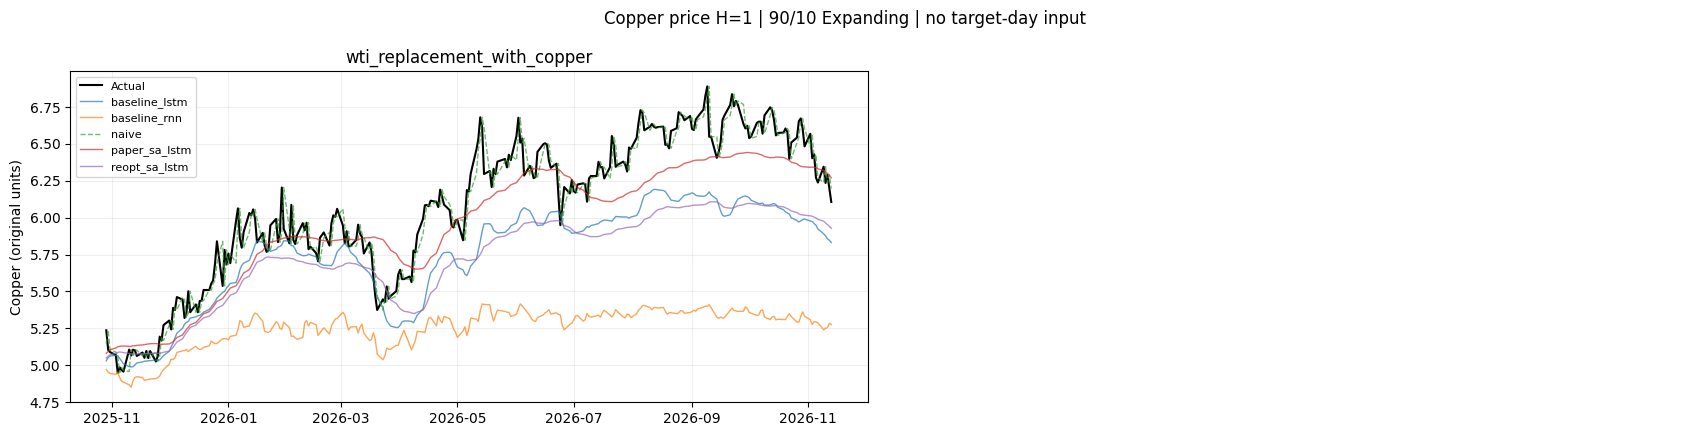

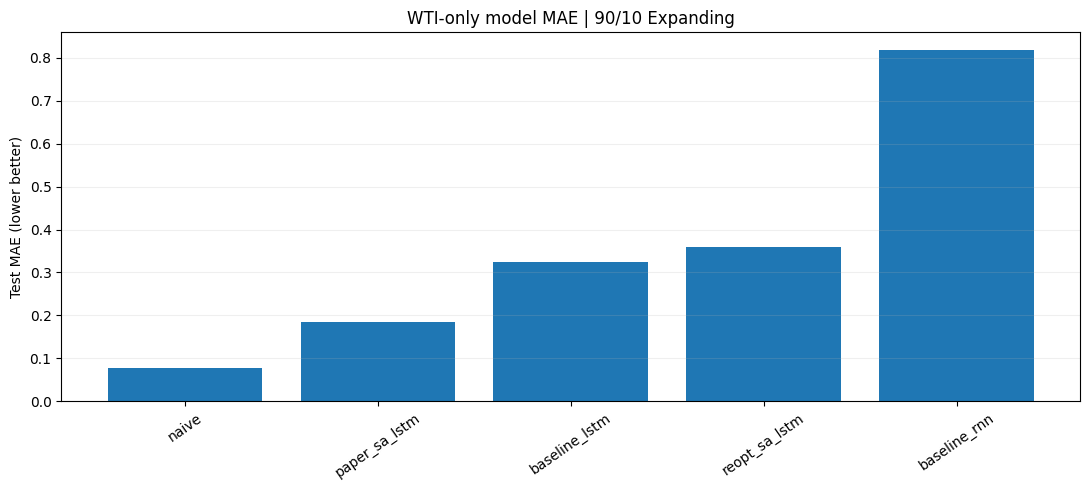

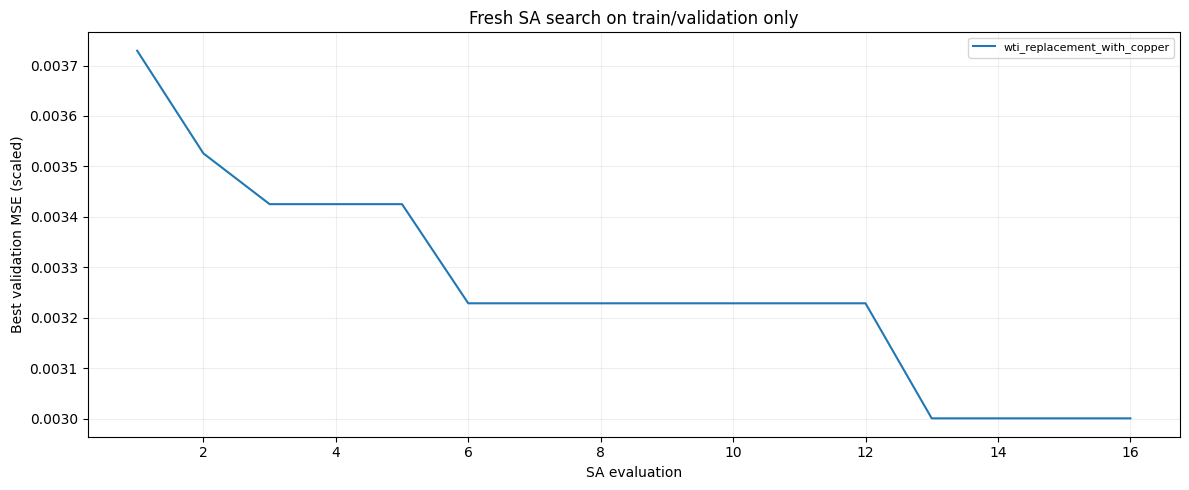

In [11]:
preds = pd.read_csv(PRED_CSV,parse_dates=['Date'])
# Same 90/10 Expanding test, plots for all configured variants.
ncols=2; nrows=int(np.ceil(len(FEATURE_SETS)/ncols))
fig,axes=plt.subplots(nrows,ncols,figsize=(17,4.4*nrows),squeeze=False)
for ax, feat in zip(axes.ravel(),FEATURE_SETS):
    sub=preds[(preds.feature_set==feat)&np.isclose(preds.ratio,PRIMARY_RATIO)&(preds.scheme=='expanding')]
    actual=sub[sub.model=='naive'].sort_values('Date')
    ax.plot(actual.Date,actual.actual,color='black',lw=1.5,label='Actual')
    for name,g in sub.groupby('model'):
        g=g.sort_values('Date')
        ax.plot(g.Date,g.pred,ls='--' if name=='naive' else '-',alpha=.7,lw=1,label=name)
    ax.set_title(feat);ax.set_ylabel('Copper (original units)');ax.grid(alpha=.2);ax.legend(fontsize=8)
for ax in axes.ravel()[len(FEATURE_SETS):]:ax.axis('off')
plt.suptitle('Copper price H=1 | 90/10 Expanding | no target-day input')
plt.tight_layout();plt.savefig(OUT/'actual_vs_predicted_all_variants.png',dpi=145);plt.show()

# WTI-only MAE by model, same 90/10 Expanding test period.
fig,ax=plt.subplots(figsize=(11,5))
sub=main.sort_values('mae')
ax.bar(sub.model, sub.mae)
ax.tick_params(axis='x',rotation=35)
ax.set_title('WTI-only model MAE | 90/10 Expanding')
ax.set_ylabel('Test MAE (lower better)')
ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(OUT/'wti_only_model_mae.png',dpi=150);plt.show()

# SA trial progress for every search. No test used for optimization.
trials=pd.read_csv(SA_PATH)
fig,ax=plt.subplots(figsize=(12,5))
for name,g in trials.groupby('feature_set'):
    g=g.sort_values('trial');ax.plot(g.trial,g.best_val_mse_scaled,label=name)
ax.set_xlabel('SA evaluation');ax.set_ylabel('Best validation MSE (scaled)')
ax.set_title('Fresh SA search on train/validation only');ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(OUT/'sa_search_convergence.png',dpi=150);plt.show()


## 10. Final manifest and ZIP — includes SA trials, best HP, all results and figures

In [12]:
runtime_mins=(time.monotonic()-JOB_START)/60
summary_lines=[
'# Copper forecasting — V22 fresh SA, WTI-only',
'Generated: '+time.strftime('%Y-%m-%d %H:%M:%S'),
'MODE: '+MODE+' | HORIZON: 1 | LOOKBACK: '+str(LOOKBACK),
'Dataset SHA256: '+dataset_sha256,
'Feature sets: '+str(FEATURE_SETS),
'Models: Naive, LSTM, SimpleRNN, Paper-HP LSTM, Fresh SA tuned LSTM',
'Strategies: '+str(SCHEMES),
'Fixed paper HP: '+str(PAPER_SA_LSTM_HP),
'Fresh SA tuned separately for every feature variant: '+str(sa_best_cache),
'SA budget/variant: '+str(CFG['sa_evals'])+' x '+str(CFG['search_epochs'])+' max epochs',
'HP search uses earliest 80/20 Expanding TRAIN/VALIDATION only; test was not consulted.',
'Spearman ranking of PRICE LEVELS motivated hypothesis, not evidence of predictive value.',
'No legacy/Paper3 retraining. Compare with historical results in the later report.',
'Paper configuration is partially reconstructed (Dense(32) is a study assumption).',
'Results are chronological holdout, NOT retrained walk-forward.',
'Experiment jobs: '+str(len(df_res)), 'Runtime minutes: %.1f'%runtime_mins,
]
(OUT/'run_summary.md').write_text('\n'.join(summary_lines),encoding='utf-8')
manifest={'version':'V22_wti_only_fresh_sa','dataset':str(DATA_PATH),'dataset_sha256':dataset_sha256,
          'feature_sets':FEATURE_SETS,'ratios':RATIOS,'schemes':SCHEMES,'seed':SEED,
          'sa_seed':SA_SEED,'sa_reference_ratio':min(RATIOS),'sa_space':SA_SPACE,'sa_best':sa_best_cache,
          'sa_evals':CFG['sa_evals'],'sa_search_epochs':CFG['search_epochs'],
          'final_epochs':CFG['epochs'],'lookback':LOOKBACK,'horizon':HORIZON}
(OUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
zip_path=OUT.parent/(OUT.name+'_results.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file():z.write(p,arcname=str(Path(OUT.name)/p.relative_to(OUT)))
print('Results ZIP:',zip_path,'MB:',round(zip_path.stat().st_size/1e6,2))


Results ZIP: /kaggle/working/copper_sa_lstm_wti_only_v22_results.zip MB: 0.48
